In [9]:
import sympy as sp
from IPython.display import display, Math
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Диференциално и интегрално смятане: Охлаждане и Термодинамика
Охлаждането отнема между 80% и 85% от общия производствен цикъл при обработката на полимери. Поради това прецизното изчисляване на времето за изстиване е критично важно за оптимизацията на продуктивността и енергийната ефективност в индустрията.

### Математически концепции
* **Диференциални уравнения – Закон на Нютон за охлаждането**
Законът на Нютон за охлаждането гласи, че скоростта на изменение на температурата на едно тяло е правопропорционална на разликата между текущата температура на тялото и температурата на околната среда:

$$\frac{dT}{dt} = -k(T - T_a)$$

При технологията шприцоване на пластмаса (*injection moulding*) прилагането на този закон има специфични инженерни особености. Той служи като **фундаментална основа за изчисляване на топлообмена**, но реалният физически процес е по-сложен поради следните фактори:
1. **Лоша топлопроводимост:** Пластмасите имат много ниска температуропроводност. Външният слой, който докосва металната матрица, изстива мигновено, образувайки твърда кора, но вътрешността (ядрото) на детайла остава гореща за много по-дълго време.
2. **Динамичен коефициент на топлопреминаване:** Когато пластмасата изстива, тя се свива. Това термично свиване я отделя леко от стената на матрицата и се образува микроскопичен въздушен слой (*air gap*). Тъй като въздухът е отличен топлинен изолатор, константата на охлаждане ($k$ от закона на Нютон) рязко намалява в хода на процеса, което допълнително забавя охлаждането в крайната му фаза.

* **Логаритмични функции и интегриране**
Чрез интегриране на частичното диференциално уравнение за топлопроводност на Фурие (при гранични условия за постоянна температура на матрицата) се стига до аналитично решение. В него охлаждането придобива експоненциален характер, а времето се изразява чрез обратната на експоненциалната функция – естествен логаритъм ($\ln$).

### Инженерна формула за охлаждане при шприцоване на пластмаса:
За изчисляване на теоретичното време за охлаждане $t_{\text{c}}$ до достигане на безопасна температура за изваждане на детайла, се използва следното уравнение:

$$t_c = \frac{h^2}{4 \times \pi^2 \times \alpha} \ln\left(\frac{4}{\pi} \times \frac{T_m - T_w}{T_e - T_w} \right)$$

**Където:**
* $h$ – максималната пълна дебелина на стената на детайла ($mm$)
* $\alpha$ – термичната дифузия (температуропроводността) на материала ($mm^2/s$)
* $T_m$ – температура на разтопената пластмаса при впръскване (°C)
* $T_w$ – температура на стената на матрицата, поддържана от охлаждащите канали (°C)
* $T_e$ – средна температура на детайла при неговото изваждане (*ejection temperature*) от матрицата (°C)





In [23]:
# Дефиниране на символи
t, s, T_m, T_w, T_e, alpha, B = sp.symbols('t s T_m T_w T_e alpha B')
t_e = sp.symbols('t_e')

# Основна функция и диференциране
T_t = T_w + (4 / sp.pi) * (T_m - T_w) * sp.exp(-B * t)
dT_dt = sp.diff(T_t, t)

# Специфична константа на Фурие (с термичен радиус s)
B_exact = sp.pi**2 * alpha / s**2
dT_dt_full = dT_dt.subs(B, B_exact)

print("Генериране формули от Python кода:")
print("-"*40)

# Поправено от T{t} на T(t)
display(Math(r"\text{1. Основна температурна функция: } T(t) = " + sp.latex(T_t)))
display(Math(r"\text{2. Диференциално смятане (Скорост на охлаждане): } \frac{dT}{dt} = " + sp.latex(dT_dt_full)))

# Интегрално смятане за средна температура
integral_T = sp.integrate(T_t.subs(B, B_exact), (t, 0, t_e))
T_average = (1 / t_e) * integral_T

display(Math(r"\text{3. Интегрално смятане (Средна температура): } \bar{T} = " + sp.latex(T_average.simplify())))


Генериране формули от Python кода:
----------------------------------------


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [26]:
# Дефиниране на математическите символи
t, T_w, T_m, alpha, s = sp.symbols('t T_w T_m alpha s')

# Коригирани специфични стойности за ПОЛИПРОПИЛЕН (PP)
full_thickness = 0.00147  # 1.47 мм пълна дебелина на стената в метри
s_val = full_thickness / 2  # s е ПОЛОВИНАТА дебелина (двустранно охлаждане) -> 0.735 мм в метри

T_m_val = 235.0    # Температура на стопилката (°C)
T_w_val = 25.0     # Температура на матрицата (°C)
T_e_val = 50.0     # Температура на изваждане (°C)
alpha_val = 8.2e-8 # Коефициент за PP (0.082 mm²/s превърнато в m²/s)

# Създаване на формулата
T_t = T_w + (4 / sp.pi) * (T_m - T_w) * sp.exp(- (sp.pi**2 * alpha * t) / (s**2))

# Заместване на вашите конкретни стойности във формулата
T_t_specific = T_t.subs({T_m: T_m_val, T_w: T_w_val, s: s_val, alpha: alpha_val})

# Показване на формулата в красив вид
print("Формулата за ПОЛИПРОПИЛЕН (PP) е записана в паметта за следващата клетка:")
display(Math(r"T(t) = " + sp.latex(T_t_specific.evalf(4))))


Формулата за ПОЛИПРОПИЛЕН (PP) е записана в паметта за следващата клетка:


<IPython.core.display.Math object>

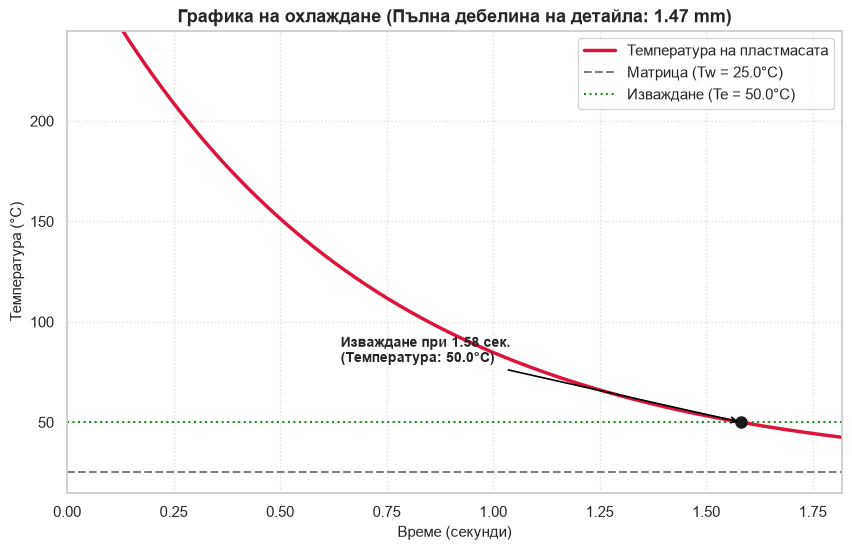

In [24]:
# Използваме директно T_t_specific от предната клетка и я превръщаме в Python функция
T_func = sp.lambdify(t, T_t_specific, 'numpy')

# Математическо изчисляване на точното време за охлаждане до T_e_val (50°C)
t_ejection = (s_val**2 / (np.pi**2 * alpha_val)) * np.log((4 / np.pi) * ((T_m_val - T_w_val) / (T_e_val - T_w_val)))

# Генериране на времеви стъпки за графиката
t_vals = np.linspace(0, t_ejection * 1.15, 1000)
T_vals = T_func(t_vals)

# Чертане на графиката по Вашите данни
plt.figure(figsize=(10, 6))
plt.plot(t_vals, T_vals, color='crimson', linewidth=2.5, label='Температура на пластмасата')

# Помощни линии за Вашите температури
plt.axhline(y=T_w_val, color='gray', linestyle='--', label=f'Матрица (Tw = {T_w_val}°C)')
plt.axhline(y=T_e_val, color='forestgreen', linestyle=':', label=f'Изваждане (Te = {T_e_val}°C)')

# Отбелязване на точката на изваждане
plt.plot(t_ejection, T_e_val, 'ko', markersize=8)
plt.annotate(f' Изваждане при {t_ejection:.2f} сек.\n (Температура: {T_e_val}°C)',
             xy=(t_ejection, T_e_val),
             xytext=(t_ejection * 0.4, T_e_val + 30), # Леко коригиран офсет, за да не излиза извън рамката
             arrowprops=dict(arrowstyle="->", color='black', linewidth=1.2),
             fontsize=10, fontweight='bold')

# ПОПРАВКА: s_val * 2 * 1000 дава реалната пълна дебелина от 1.47 mm
plt.title(f'Графика на охлаждане (Пълна дебелина на детайла: {s_val * 2 * 1000:.2f} mm)', fontsize=13, fontweight='bold')
plt.xlabel('Време (секунди)', fontsize=11)
plt.ylabel('Температура (°C)', fontsize=11)
plt.xlim(0, t_vals.max())
plt.ylim(T_w_val - 10, T_m_val + 10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right', fontsize=11)

plt.show()


###  Температурна крива на охлаждане във времето (Червената крива)
Тази графика проследява динамиката на температурата в ядрото (геометричния център) на пластмасовата стена от момента на впръскване в матрицата до момента на отваряне на инструмента.

* **Червената експоненциална крива ($T(t)$):** Тя започва от $235^\circ\text{C}$ (температура на стопилката $T_m$). В началната фаза пластмасата изстива изключително бързо поради големия температурен градиент спрямо охладения метал. С течение на времето топлообменът се забавя и кривата се заглажда експоненциално съгласно интегрирания закон на Фурие.
* **Сивата прекъсната линия ($T_w = 25^\circ\text{C}$):** Термодинамична асимптота, дефинираща температурата на стената на матрицата. Пластмасовият детайл не може да изстине под тази граница в рамките на цикъла.
* **Зелената пунктирана линия ($T_e = 50^\circ\text{C}$):** Критерият за край на фазата – температурата за безопасно изваждане на детайла (*ejection temperature*).
* **Черната точка ("Изваждане при 1.58 сек"):** Критичен времеви маркер. Показва точния момент, в който детайлът е придобил достатъчна структурна стабилност (твърдост), за да издържи силата на избутващите щифтове без риск от пластична деформация. За дебелина от $1.47\text{ mm}$ този преход отнема точно $1.58$ секунди.



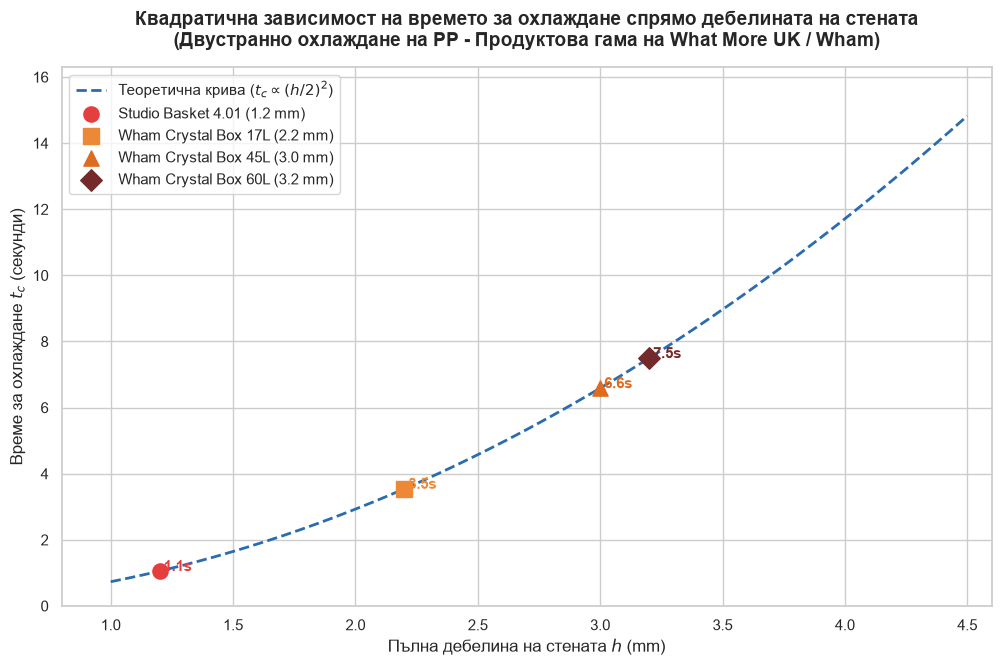

In [25]:
# Задаване на стил на графиката
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 7))

# Дефиниране на математическата функция за охлаждане (Закон на Фурие)
# Уеднаквени стойности за ПОЛИПРОПИЛЕН (PP) от предната клетка
T_m = 235.0  # Температура на стопилката (°C)
T_w = 25.0   # Температура на матрицата (°C)
T_e = 50.0   # Температура на изваждане (°C)
alpha = 0.082  # Термична дифузия (mm²/s)

# Изчисляване на термодинамичната константа
log_part = np.log((4 / np.pi) * ((T_m - T_w) / (T_e - T_w)))

# Генерираме непрекъснат масив от реални дебелини (h) от 1.0 mm до 4.5 mm
h_line = np.linspace(1.0, 4.5, 200)

# Делим h_line на 2, за да получим термичния радиус s (двустранно охлаждане)
t_cooling_line = (((h_line / 2)**2) / (np.pi**2 * alpha)) * log_part

#  Начертаване на теоретичната параболична крива
plt.plot(h_line, t_cooling_line, color='#2b6cb0', linestyle='--', linewidth=2, label=r'Теоретична крива ($t_c \propto (h/2)^2$)')

# Поставяне на реални точки от гамата на Wham за контраст

wham_examples = {
    "Studio Basket 4.01": (1.2, (((1.2 / 2)**2) / (np.pi**2 * alpha)) * log_part, '#e53e3e', 'o'),
    "Wham Crystal Box 17L": (2.2, (((2.2 / 2)**2) / (np.pi**2 * alpha)) * log_part, '#ed8936', 's'),
    "Wham Crystal Box 45L": (3.0, (((3.0 / 2)**2) / (np.pi**2 * alpha)) * log_part, '#dd6b20', '^'),
    "Wham Crystal Box 60L": (3.2, (((3.2 / 2)**2) / (np.pi**2 * alpha)) * log_part, '#742a2a', 'D')
}

# Поставяме точките върху графиката
for name, (h_val, t_val, color, marker) in wham_examples.items():
    plt.scatter(h_val, t_val, color=color, s=120, marker=marker, zorder=5, label=f"{name} ({h_val} mm)")
    # Добавяне на текстов етикет до всяка точка (закръглен до първия знак след запетаята за точност)
    plt.annotate(f" {t_val:.1f}s", (h_val, t_val), fontsize=11, fontweight='bold', color=color)

# Оформяне на графиката (Заглавия и оси)
plt.title("Квадратична зависимост на времето за охлаждане спрямо дебелината на стената\n(Двустранно охлаждане на PP - Продуктова гама на What More UK / Wham)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Пълна дебелина на стената $h$ (mm)", fontsize=12)
plt.ylabel("Време за охлаждане $t_c$ (секунди)", fontsize=12)
plt.xlim(0.8, 4.6)
plt.ylim(0, max(t_cooling_line) * 1.1)
plt.legend(loc="upper left", fontsize=11)

# Показване на графиката
plt.show()


###  Параболична зависимост на времето спрямо дебелината (Синята прекъсната крива)
Визуализацията илюстрира фундаменталното правило в полимерното инженерство: **времето за охлаждане нараства квадратично спрямо дебелината на стената.**

* **Синята параболична крива ($t_c \propto (h/2)^2$):** Нелинейният характер на кривата произтича от ниската температуропроводност на полипропилена ($\alpha = 0.082\text{ mm}^2/\text{s}$). С увеличаване на дебелината, съпротивлението срещу топлинния поток от вътрешността към повърхността нараства експоненциално. Удвояването на дебелината изисква **четири пъти** повече време за охлаждане.
* **Позициониране на продуктите на Wham:** Точките показват къде реалните изделия от гамата се намират върху теоретичната парабола:
    * *Studio Basket 4.01 ($1.2\text{ mm}$)* се намира в началото на кривата с теоретично време от едва **$1.1$ секунди**.
    * *Wham Crystal Box 60L ($3.2\text{ mm}$)* е позициониран високо в десния край на параболата, изисквайки **$7.5$ секунди** охлаждане.
* **Производствен извод:** Макар разликата в дебелините да е само $2.0\text{ mm}$, квадратичният ефект налага машината да чака близо **7 пъти по-дълго** за охлаждането на голямата кутия, което директно увеличава общото време на производствения цикъл и себестойността на продукта.

